In [3]:
%pip install seaborn
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt


Note: you may need to restart the kernel to use updated packages.


In [4]:
from pathlib import Path
data_path = Path(r"C:\Users\govin\Documents\shopintent-ml\data\raw\online_shoppers_intention.csv")

In [5]:
df =pd.read_csv(data_path)

In [6]:
print("Dataset shape",df.shape)
df.head()

Dataset shape (12330, 18)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  str    
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  
 14  TrafficType              12330 no

In [9]:
print(df.isnull().sum())
print(df.duplicated().sum())
display(df.describe())
print(df["Revenue"].value_counts())

Administrative             0
Administrative_Duration    0
Informational              0
Informational_Duration     0
ProductRelated             0
ProductRelated_Duration    0
BounceRates                0
ExitRates                  0
PageValues                 0
SpecialDay                 0
Month                      0
OperatingSystems           0
Browser                    0
Region                     0
TrafficType                0
VisitorType                0
Weekend                    0
Revenue                    0
dtype: int64
125


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,OperatingSystems,Browser,Region,TrafficType
count,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000
mean,2.315166,80.818611,0.503569,34.472398,31.731468,1194.746220,0.022191,0.043073,5.889258,0.061427,2.124006,2.357097,3.147364,4.069586
std,3.321784,176.779107,1.270156,140.749294,44.475503,1913.669288,0.048488,0.048597,18.568437,0.198917,0.911325,1.717277,2.401591,4.025169
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,1.000000
25%,0.000000,0.000000,0.000000,0.000000,7.000000,184.137500,0.000000,0.014286,0.000000,0.000000,2.000000,2.000000,1.000000,2.000000
50%,1.000000,7.500000,0.000000,0.000000,18.000000,598.936905,0.003112,0.025156,0.000000,0.000000,2.000000,2.000000,3.000000,2.000000
75%,4.000000,93.256250,0.000000,0.000000,38.000000,1464.157214,0.016813,0.050000,0.000000,0.000000,3.000000,2.000000,4.000000,4.000000
max,27.000000,3398.750000,24.000000,2549.375000,705.000000,63973.522230,0.200000,0.200000,361.763742,1.000000,8.000000,13.000000,9.000000,20.000000


Revenue
False    10422
True      1908
Name: count, dtype: int64


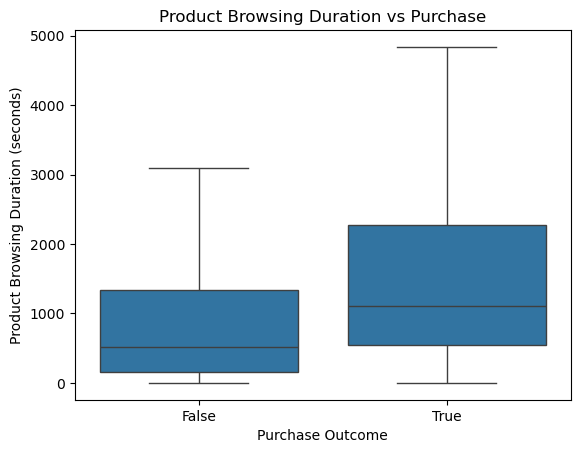

In [10]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.boxplot(
    data=df,
    x="Revenue",
    y="ProductRelated_Duration",
    showfliers=False
)

plt.title("Product Browsing Duration vs Purchase")
plt.xlabel("Purchase Outcome")
plt.ylabel("Product Browsing Duration (seconds)")
plt.show()

In [11]:
features = [
    "Administrative",
    "Informational",
    "ProductRelated",
    "ProductRelated_Duration",
    "BounceRates",
    "ExitRates",
    "PageValues"
]

df.groupby("Revenue")[features].median().round(3)


,Administrative,Informational,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues
Revenue,,,,,,,
False,0.0,0.0,16.0,510.190,0.004,0.029,0.000
True,2.0,0.0,29.0,1109.906,0.000,0.016,16.758


In [12]:
visitor_analysis = (
    df.groupby("VisitorType")["Revenue"]
      .agg(["count", "mean"])
      .rename(columns={
          "count": "Total_Sessions",
          "mean": "Purchase_Rate"
      })
)

visitor_analysis["Purchase_Rate"] *= 100

display(visitor_analysis.round(2))

,Total_Sessions,Purchase_Rate
VisitorType,,
New_Visitor,1694,24.91
Other,85,18.82
Returning_Visitor,10551,13.93


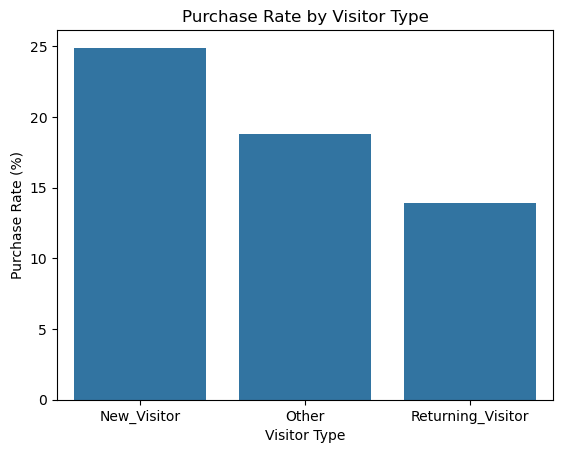

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.barplot(
    data=visitor_analysis.reset_index(),
    x="VisitorType",
    y="Purchase_Rate"
)

plt.title("Purchase Rate by Visitor Type")
plt.ylabel("Purchase Rate (%)")
plt.xlabel("Visitor Type")
plt.show()


In [14]:

from sklearn.model_selection import train_test_split


X = df.drop(columns=["Revenue"])
y = df["Revenue"].astype(int)

# Create 80% training and 20% testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training purchase rate:", round(y_train.mean() * 100, 2), "%")
print("Testing purchase rate:", round(y_test.mean() * 100, 2), "%")

Training features: (9864, 17)
Testing features: (2466, 17)
Training purchase rate: 15.47 %
Testing purchase rate: 15.49 %


In [15]:

from sklearn.model_selection import train_test_split


X_dev = X_train.copy()

X_dev = X_dev.drop(columns=["PageValues"], errors="ignore")


category_codes = [
    "OperatingSystems",
    "Browser",
    "Region",
    "TrafficType"
]

for col in category_codes:
    if col in X_dev.columns:
        X_dev[col] = X_dev[col].astype(str)

# Create training and validation datasets
X_fit, X_val, y_fit, y_val = train_test_split(
    X_dev,
    y_train,
    test_size=0.25,
    random_state=42,
    stratify=y_train
)

print("Training:", X_fit.shape)
print("Validation:", X_val.shape)


Training: (7398, 16)
Validation: (2466, 16)


In [17]:

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression



numeric_features = X_fit.select_dtypes(
    include=["number"]
).columns.tolist()


categorical_features = [
    col for col in X_fit.columns
    if col not in numeric_features
]

print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)



numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])


categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])



preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])



model = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])

print("\nML pipeline created successfully!")


Numerical features: ['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'SpecialDay']
Categorical features: ['Month', 'OperatingSystems', 'Browser', 'Region', 'TrafficType', 'VisitorType', 'Weekend']

ML pipeline created successfully!


In [19]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression

numeric_features = X_fit.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = [
    col for col in X_fit.columns
    if col not in numeric_features
]

print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)

print("\nMissing categorical values:")
print(X_fit[categorical_features].isna().sum())


numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])


categorical_pipeline = Pipeline([
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

# Create ML model
model = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])

print("\nML pipeline created successfully!")


Numerical features: ['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'SpecialDay']
Categorical features: ['Month', 'OperatingSystems', 'Browser', 'Region', 'TrafficType', 'VisitorType', 'Weekend']

Missing categorical values:
Month               0
OperatingSystems    0
Browser             0
Region              0
TrafficType         0
VisitorType         0
Weekend             0
dtype: int64

ML pipeline created successfully!


In [20]:
model.fit(X_fit, y_fit)

print("Model trained successfully!")

y_pred = model.predict(X_val)
y_proba = model.predict_proba(X_val)[:, 1]

print("Predictions:", y_pred[:10])
print("Probabilities:", y_proba[:10].round(3))

Model trained successfully!
Predictions: [1 0 0 0 0 0 0 0 0 0]
Probabilities: [0.53  0.116 0.055 0.108 0.343 0.222 0.08  0.073 0.091 0.2  ]


In [21]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

print("Accuracy:", accuracy_score(y_val, y_pred))
print("Precision:", precision_score(y_val, y_pred, zero_division=0))
print("Recall:", recall_score(y_val, y_pred, zero_division=0))
print("F1:", f1_score(y_val, y_pred, zero_division=0))
print("ROC-AUC:", roc_auc_score(y_val, y_proba))

Accuracy: 0.8438767234387672
Precision: 0.4090909090909091
Recall: 0.023622047244094488
F1: 0.04466501240694789
ROC-AUC: 0.7409908293837372


In [22]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

rf_model = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        max_depth=12,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

rf_model.fit(X_fit, y_fit)

print("Random Forest trained successfully!")

rf_pred = rf_model.predict(X_val)
rf_proba = rf_model.predict_proba(X_val)[:, 1]

Random Forest trained successfully!


In [23]:

import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

def evaluate_model(name, y_true, y_pred, y_prob):
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1": f1_score(y_true, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, y_prob),
        "PR-AUC": average_precision_score(y_true, y_prob)
    }

results = pd.DataFrame([
    evaluate_model("Logistic Regression", y_val, y_pred, y_proba),
    evaluate_model("Random Forest", y_val, rf_pred, rf_proba)
])

display(results.round(4))


,Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,Logistic Regression,0.8439,0.4091,0.0236,0.0447,0.7410,0.3201
1,Random Forest,0.7105,0.2937,0.6220,0.3990,0.7652,0.3499


In [24]:
%pip install xgboost

   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.5/48.9 MB 1.6 MB/s eta 0:00:31
    --------------------------------------- 0.8/48.9 MB 1.6 MB/s eta 0:00:30
    --------------------------------------- 1.0/48.9 MB 1.3 MB/s eta 0:00:38
    --------------------------------------- 1.0/48.9 MB 1.3 MB/s eta 0:00:38
   - -------------------------------------- 1.3/48.9 MB 1.2 MB/s eta 0:00:40
   - -------------------------------------- 1.6/48.9 MB 1.1 MB/s eta 0:00:42
   - -------------------------------------- 1.8/48.9 MB 1.1 MB/s eta 0:00:42
   - -------------------------------------- 2.1/48.9 MB 1.1 MB/s eta 0:00:43
   - -------------------------------------- 2.1/48.9 MB 1.1 MB/s eta 0:00:43
   - -------------------------------------- 2.4/48.9 MB 1.1 MB/s eta 0:00:44
   -- ------------------------------------- 2.6/48.9 MB 1.1 MB/s eta 0:00:44
   -- -------

In [27]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

# Reusable function to evaluate any classification model
def evaluate(y_true, predictions, probabilities):
    return {
        "Accuracy": accuracy_score(y_true, predictions),
        "Precision": precision_score(
            y_true, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_true, predictions, zero_division=0
        ),
        "F1": f1_score(
            y_true, predictions, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(
            y_true, probabilities
        ),
        "PR-AUC (AP)": average_precision_score(
            y_true, probabilities
        )
    }

print("Evaluation function defined successfully!")


Evaluation function defined successfully!


In [28]:

import pandas as pd

results = pd.DataFrame({
    "Logistic Regression": evaluate(
        y_val, y_pred, y_proba
    ),
    "Random Forest": evaluate(
        y_val, rf_pred, rf_proba
    ),
    "XGBoost": evaluate(
        y_val, xgb_pred, xgb_proba
    )
}).T

display(results.round(4))


,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC (AP)
Logistic Regression,0.8439,0.4091,0.0236,0.0447,0.7410,0.3201
Random Forest,0.7105,0.2937,0.6220,0.3990,0.7652,0.3499
XGBoost,0.8451,0.4944,0.1155,0.1872,0.7655,0.3560


In [29]:

from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from xgboost import XGBClassifier

# Create model pipeline
tuning_pipeline = Pipeline([
    ("preprocessing", clone(preprocessor)),
    ("classifier", XGBClassifier(
        objective="binary:logistic",
        eval_metric="logloss",
        tree_method="hist",
        random_state=42,
        n_jobs=-1
    ))
])

# Define hyperparameters to explore
param_grid = {
    "classifier__n_estimators": [100, 200, 300],
    "classifier__max_depth": [3, 4, 6],
    "classifier__learning_rate": [0.01, 0.05, 0.1],
    "classifier__subsample": [0.8, 1.0],
    "classifier__colsample_bytree": [0.8, 1.0]
}

cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

search = RandomizedSearchCV(
    estimator=tuning_pipeline,
    param_distributions=param_grid,
    n_iter=8,
    scoring="average_precision",
    cv=cv,
    random_state=42,
    n_jobs=1,
    verbose=1
)

# Tune using training data only
search.fit(X_fit, y_fit)

print("Best Parameters:")
print(search.best_params_)

print("\nBest Cross-Validation Average Precision:")
print(round(search.best_score_, 4))


Fitting 3 folds for each of 8 candidates, totalling 24 fits
Best Parameters:
{'classifier__subsample': 0.8, 'classifier__n_estimators': 100, 'classifier__max_depth': 6, 'classifier__learning_rate': 0.05, 'classifier__colsample_bytree': 0.8}

Best Cross-Validation Average Precision:
0.3779


In [30]:

# Best model selected by cross-validation
best_xgb = search.best_estimator_

# Predict on validation data
tuned_pred = best_xgb.predict(X_val)
tuned_proba = best_xgb.predict_proba(X_val)[:, 1]

# Reuse our evaluation function
tuned_results = evaluate(
    y_val,
    tuned_pred,
    tuned_proba
)

print("Tuned XGBoost Performance:")

for metric, value in tuned_results.items():
    print(f"{metric}: {value:.4f}")


Tuned XGBoost Performance:
Accuracy: 0.8443
Precision: 0.4769
Recall: 0.0814
F1: 0.1390
ROC-AUC: 0.7648
PR-AUC (AP): 0.3556


In [31]:

import pandas as pd

comparison = pd.DataFrame({
    "Original XGBoost": evaluate(
        y_val, xgb_pred, xgb_proba
    ),
    "Tuned XGBoost": tuned_results
}).T

display(comparison.round(4))


,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC (AP)
Original XGBoost,0.8451,0.4944,0.1155,0.1872,0.7655,0.3560
Tuned XGBoost,0.8443,0.4769,0.0814,0.1390,0.7648,0.3556


In [32]:

from sklearn.metrics import (
    brier_score_loss,
    log_loss,
    average_precision_score
)
import pandas as pd

# Evaluate original and tuned XGBoost
probability_results = pd.DataFrame({
    "Original XGBoost": {
        "Brier Score": brier_score_loss(y_val, xgb_proba),
        "Log Loss": log_loss(y_val, xgb_proba),
        "Average Precision": average_precision_score(y_val, xgb_proba)
    },
    "Tuned XGBoost": {
        "Brier Score": brier_score_loss(y_val, tuned_proba),
        "Log Loss": log_loss(y_val, tuned_proba),
        "Average Precision": average_precision_score(y_val, tuned_proba)
    }
}).T

display(probability_results.round(4))


,Brier Score,Log Loss,Average Precision
Original XGBoost,0.1155,0.3684,0.3560
Tuned XGBoost,0.1151,0.3682,0.3556


In [33]:

from sklearn.calibration import CalibratedClassifierCV
from sklearn.base import clone

# Calibrate the tuned XGBoost pipeline
calibrated_xgb = CalibratedClassifierCV(
    estimator=clone(best_xgb),
    method="sigmoid",
    cv=3
)

calibrated_xgb.fit(X_fit, y_fit)

# Predict probabilities on validation data
calibrated_proba = calibrated_xgb.predict_proba(X_val)[:, 1]

print("Calibration completed successfully!")

print("Before calibration Brier Score:",
      round(brier_score_loss(y_val, tuned_proba), 4))

print("After calibration Brier Score:",
      round(brier_score_loss(y_val, calibrated_proba), 4))


Calibration completed successfully!
Before calibration Brier Score: 0.1151
After calibration Brier Score: 0.1155


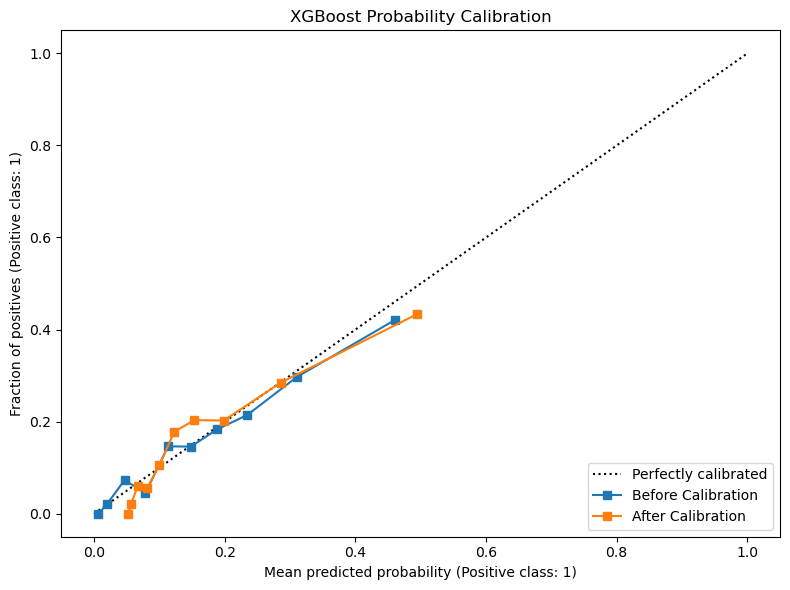

In [34]:

from sklearn.calibration import CalibrationDisplay
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 6))

CalibrationDisplay.from_predictions(
    y_val,
    tuned_proba,
    n_bins=10,
    strategy="quantile",
    name="Before Calibration",
    ax=ax
)

CalibrationDisplay.from_predictions(
    y_val,
    calibrated_proba,
    n_bins=10,
    strategy="quantile",
    name="After Calibration",
    ax=ax
)

plt.title("XGBoost Probability Calibration")
plt.tight_layout()
plt.show()
